# Relative Illumination

Relative illumination (RI) is the image irradiance across the field, normalized to its maximum, for a uniform, planar, Lambertian object. It is a key specification for camera and sensor optics.

`RelativeIllumination` follows M. Rimmer, "Relative illumination calculations", *Proc. SPIE* 655, 99 (1986). Radiance is conserved through the system apart from transmission losses, so the irradiance at an image point is proportional to the **projected solid angle** of the exit pupil seen from that point. In image space, that is the area the rays cover in direction-cosine space $(L, M)$. Vignetting, pupil aberrations, telecentricity and changes of F-number across the field all change this area, so the result is in general **not** a cos⁴ curve.

In [1]:
from __future__ import annotations

import numpy as np

from optiland.analysis import RelativeIllumination
from optiland.physical_apertures import RadialAperture
from optiland.samples.objectives import CookeTriplet

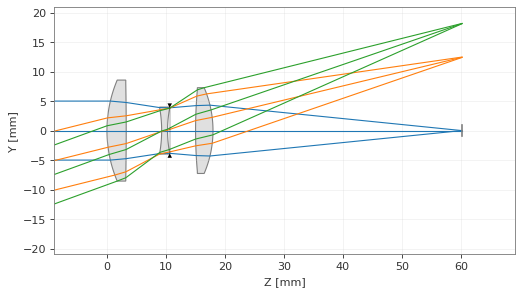

In [2]:
lens = CookeTriplet()
fig, ax = lens.draw()

By default the analysis uses the primary wavelength (relative illumination is monochromatic), 32 field points from the axis to the full field, and a pupil sampling of about 64 rays across the pupil diameter.

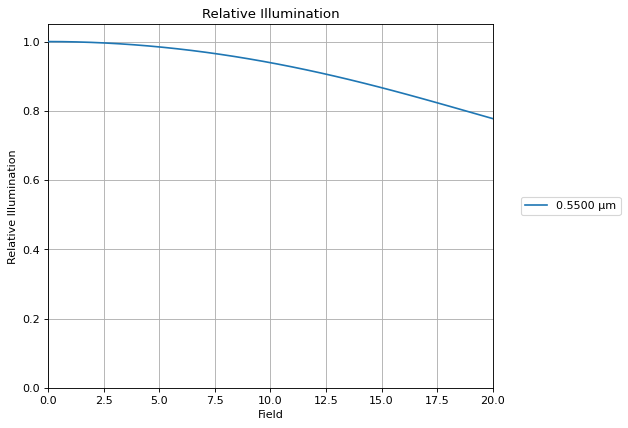

In [3]:
ri = RelativeIllumination(lens)
fig, ax = ri.view()

## Comparison with cos⁴

The cos⁴ "law" holds only for a thin, slow, aberration-free lens with the stop at the lens. The Cooke triplet, with its stop near the middle element and a 20° half field, comes close to it:

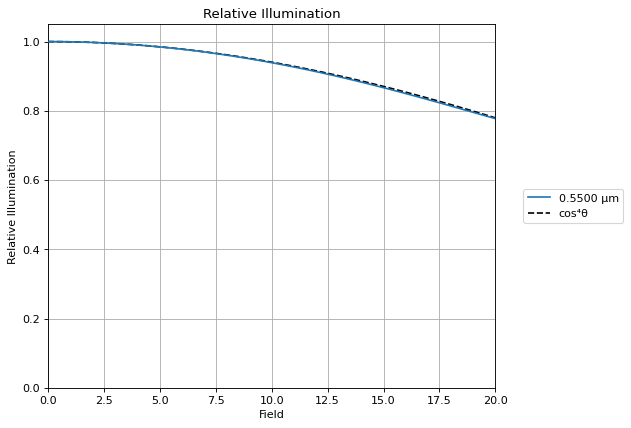

In [4]:
field = np.asarray(ri.data["Hy"]) * lens.fields.max_field
cos4 = np.cos(np.radians(field)) ** 4

fig, ax = ri.view()
ax.plot(field, cos4, "k--", label="cos⁴θ")
ax.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
fig.tight_layout()

A wide-angle lens is a different story. In this 100° field-of-view design, the exit pupil grows and tilts toward the off-axis image points (pupil coma), so the illumination stays almost flat across the field, while cos⁴ falls to 0.17 at 50°. This lens is even slightly brighter at the edge than on axis.

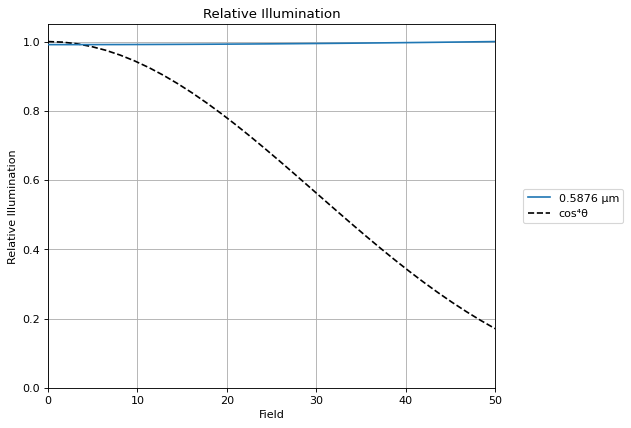

In [5]:
from optiland.samples.objectives import WideAngle100FOV

wide = WideAngle100FOV()
ri_wide = RelativeIllumination(wide)

field = np.asarray(ri_wide.data["Hy"]) * wide.fields.max_field
fig, ax = ri_wide.view()
ax.plot(field, np.cos(np.radians(field)) ** 4, "k--", label="cos⁴θ")
ax.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
fig.tight_layout()

## Ray aiming

The pupil rays follow the optic's ray aiming. The Cooke triplet sample uses paraxial aiming, so the off-axis beams fill the *paraxial* entrance pupil, which slightly underfills the real stop. Robust ray aiming fills the real stop at every field, and the relative illumination at the edge of the field rises noticeably. For lenses with large pupil aberrations, use real ray aiming.

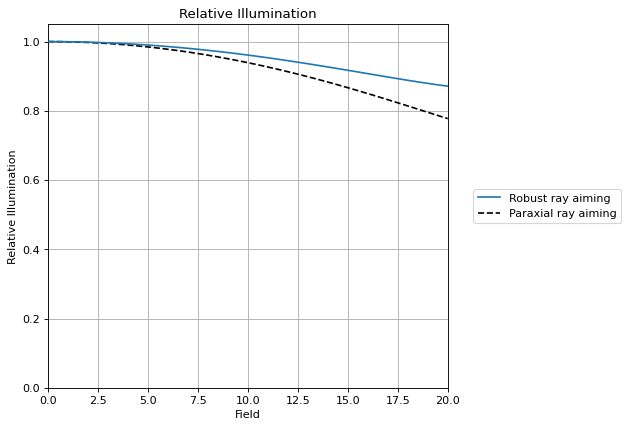

In [6]:
aimed = CookeTriplet()
aimed.ray_tracer.set_aiming("robust")
ri_aimed = RelativeIllumination(aimed)

field = np.asarray(ri_aimed.data["Hy"]) * aimed.fields.max_field
fig, ax = ri_aimed.view()
ax.lines[0].set_label("Robust ray aiming")
ax.plot(field, ri.data["relative_illumination"][0], "k--", label="Paraxial ray aiming")
ax.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
fig.tight_layout()

## Data

`ri.data` holds the normalized field coordinates, the relative illumination, the unnormalized projected solid angle (`"irradiance"`, in sr, weighted by transmission), and a reliability flag per field.

In [7]:
ri = RelativeIllumination(lens, num_fields=6)
print(" Hy     RI      irradiance (sr)  reliable")
for hy, value, area, ok in zip(
    ri.data["Hy"],
    ri.data["relative_illumination"][0],
    ri.data["irradiance"][0],
    ri.data["reliable"][0],
    strict=True,
):
    print(f"{hy:4.2f}  {value:6.4f}  {area:15.6f}  {ok}")

 Hy     RI      irradiance (sr)  reliable
0.00  1.0000         0.031671  True
0.20  0.9901         0.031357  True
0.40  0.9607         0.030427  True
0.60  0.9130         0.028916  True
0.80  0.8498         0.026913  True
1.00  0.7775         0.024623  True


## Vignetting

Clipping the front lens to a radius of 6 mm cuts the off-axis beams. The relative illumination drops at the fields where rays are vignetted, while the on-axis beam is untouched.

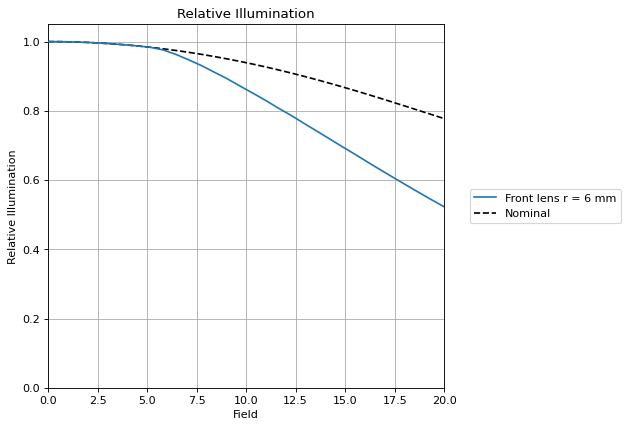

In [8]:
vignetted = CookeTriplet()
vignetted.surfaces[1].aperture = RadialAperture(r_max=6.0)

nominal = RelativeIllumination(CookeTriplet(), num_pupil=128)
clipped = RelativeIllumination(vignetted, num_pupil=128)

field = np.asarray(nominal.data["Hy"]) * vignetted.fields.max_field
fig, ax = clipped.view()
ax.lines[0].set_label("Front lens r = 6 mm")
ax.plot(
    field,
    nominal.data["irradiance"][0] / max(nominal.data["irradiance"][0]),
    "k--",
    label="Nominal",
)
ax.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
fig.tight_layout()

## How to read the plot, and limits

- **RI = 1** is the brightest field point, which is not always on axis (some wide-angle lenses are brightest at the edge).
- Transmission losses (coatings, absorption, apodization) are included through the traced ray intensity.
- The method assumes that the image surface is a good conjugate of the object, so that rays from one field point land close together. Strong defocus or field curvature at the image surface make the result differ from the true irradiance.
- If rays from different parts of the pupil reach the same image-space direction (a caustic in direction space), the area no longer measures the irradiance. The analysis then emits a `RuntimeWarning`, sets `data["reliable"]` to `False` for that field, and marks it with an `x` in the plot.
- Only planar image surfaces are supported.